EDA_ PROJECT:
"AI Usage And Impact On Students And Professionals"

In [1]:
# Installing all the necessary Libraries:
!pip install NumPy --quiet
!pip install Pandas --quiet
!pip install matplotlib seaborn --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 119.9 MB/s  0:00:00
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0


In [2]:
# IMPORT:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, accuracy_score, confusion_matrix, classification_report, precision_score, recall_score, f1_score
from sklearn.pipeline import make_pipeline
from keras.models import Sequential
from keras.layers import Dense

**STEP NO 01-02: LOAD, INSPECT & PLAN APPROACH**

In [3]:
# LOAD AND READ:
df = pd.read_csv("AI_Usage_and_Impact_on_Students_and_Professionals.csv")
print(df)

    User_ID     Age  Gender         Country     User_Type Education_Level  \
0     U0269      30    Male  United Kingdom  Professional        Master's   
1     U0217      30    Male   United States  Professional      Bachelor's   
2     U0152      17    Male          Canada       Student             NaN   
3     U0264      35  FEMALE          Brazil  Professional      Bachelor's   
4     U0263      19  Female          Canada       Student   Undergraduate   
..      ...     ...     ...             ...           ...             ...   
295   U0066     NaN  Female   United States  Professional      Bachelor's   
296   U0094      43    Male         Nigeria  Professional         Diploma   
297   U0136      48    Male          Brazil  Professional         Diploma   
298   U0002      31  Female        Pakistan  Professional         Diploma   
299   U0130  36 yrs    Male   United States  Professional         Diploma   

                                          Profession Monthly_Income  \
0   

In [4]:
print(df.head())

  User_ID Age  Gender         Country     User_Type Education_Level  \
0   U0269  30    Male  United Kingdom  Professional        Master's   
1   U0217  30    Male   United States  Professional      Bachelor's   
2   U0152  17    Male          Canada       Student             NaN   
3   U0264  35  FEMALE          Brazil  Professional      Bachelor's   
4   U0263  19  Female          Canada       Student   Undergraduate   

                                        Profession Monthly_Income  \
0                                 Business Analyst           5421   
1                      Customer Support Specialist           8903   
2                         Computer Science Student            402   
3  Desenvolvedora de Software / Software Developer           1367   
4                                  Biology Student            438   

         AI_Tool        AI_Purpose AI_Usage_Hours_Per_Day  \
0        ChatGPT       Office Work                  2 hrs   
1        ChatGPT  Customer Support  

In [5]:
print(df.shape)

(300, 19)


In [6]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      300 non-null    object 
 1   Age                          277 non-null    object 
 2   Gender                       290 non-null    object 
 3   Country                      290 non-null    object 
 4   User_Type                    300 non-null    object 
 5   Education_Level              287 non-null    object 
 6   Profession                   285 non-null    object 
 7   Monthly_Income               290 non-null    object 
 8   AI_Tool                      289 non-null    object 
 9   AI_Purpose                   287 non-null    object 
 10  AI_Usage_Hours_Per_Day       293 non-null    object 
 11  Tasks_Performed              282 non-null    object 
 12  Monthly_AI_Cost              288 non-null    object 
 13  Productivity_Score  

In [7]:
print(df.describe())

       Productivity_Score  Accuracy_Rating  Satisfaction_Score
count          284.000000       285.000000          293.000000
mean             5.230282         3.428070            6.146758
std              1.817193         0.855338            1.517805
min              1.600000         2.000000            3.000000
25%              3.900000         3.000000            5.000000
50%              5.000000         4.000000            6.000000
75%              6.500000         4.000000            7.000000
max             10.000000         5.000000           10.000000


List out: which columns are numeric, which are categorical, which (if any) look like dates or IDs?

In [8]:
#  Categorical Columns are:
# 1. Age   2. Gender   3. Country  4.Education_Level   5.Profession     6.User_Type    7.AI_Tool   8. AI_Purpose  9.Task_Performed  10. Would_Recommend

#  Numerical Columns are:
# 1. User_ID  2. Monthly_Income   3.Time_Saved_Hours_Per_Week      4. Work_or_Study_Hours_Per_Day   5. AI_Usage_Hours_Per_Day     6. Productivity_Score    7.Accuracy_Rating
# 8. Satisfaction_Score   9. Monthly_AI_Cost

In [9]:
# ABOUT DATA SET:
# This Data Set consists of 300 rows and 19 columns. This is about how students and professionals use AI tools
# and how AI affects their productivity,accuracy,satisfaction and Time saved.Also demographic data ,purpose of AI use and work or study related outcomes.

# Q.1: Using AI for more hours per day lead to higher productivity score? And which Ai tools are used by the largest proportion of users?And Also which Ai tool has the gighest productivity?
# Q.2: Difference in productivity levels between students and professionals?
# Q.3: Time saved,Satisfaction, and AI usage,Monthly cost on AI tools, which factor have the strongest relation with productivity? People with higher Satisfactin scores would recmmond AI tools?

STEP NO 03: CLEAN , TRANSFORM & EXPLORE

In [10]:
# Duplcate Rows:
print("Duplicate Rows: " ,df.duplicated().sum())

Duplicate Rows:  12


In [11]:
# Drop Duplicate Rows:

df = df.drop_duplicates().reset_index(drop = True)
print("After Dropping Duplicate Rows: ", df.shape)

After Dropping Duplicate Rows:  (288, 19)


In [12]:
# Conversion From text to Numeric :
numeric_colms = [
    "Age", "Monthly_Income", "AI_Usage_Hours_Per_Day",
    "Monthly_AI_Cost", "Time_Saved_Hours_Per_Week",
    "Work_or_Study_Hours_Per_Day"
]

for col in numeric_colms:
  df[col]=pd.to_numeric( df[col].astype(str).str.replace("$","",regex=False)
  .str.replace(",","", regex = False).str.extract(r"([-+]?\d*\.?\d+)")[0],
  errors = "coerce"
  )

print(df[numeric_colms].dtypes)

Age                            float64
Monthly_Income                 float64
AI_Usage_Hours_Per_Day         float64
Monthly_AI_Cost                float64
Time_Saved_Hours_Per_Week      float64
Work_or_Study_Hours_Per_Day    float64
dtype: object


In [13]:
# Cleaning Messy Text Columns:
txt_colms = [
    "Gender","Country","Education_Level",
    "AI_Tool","AI_Purpose","Would_Recommend"
]
for col in txt_colms:
  df[col] = df[col].astype("string").str.strip()

df["Country"] = df["Country"].str.title()
df["Country"] = df["Country"].replace({
      "U.K.": "United Kingdom"
  })

df["AI_Tool"] = (
      df["AI_Tool"].str.replace(r"\s+"," ", regex = True).str.title()
  )
print(df[txt_colms])


     Gender         Country Education_Level            AI_Tool  \
0      Male  United Kingdom        Master's            Chatgpt   
1      Male   United States      Bachelor's            Chatgpt   
2      Male          Canada            <NA>           Chat Gpt   
3    FEMALE          Brazil      Bachelor's            Meta Ai   
4    Female          Canada   Undergraduate      Perplexity Ai   
..      ...             ...             ...                ...   
283  Female   United States      Bachelor's  Microsoft Copilot   
284    Male         Nigeria         Diploma            Chatgpt   
285    Male          Brazil         Diploma      Google Gemini   
286  Female        Pakistan         Diploma            Chatgpt   
287    Male   United States         Diploma           Chat Gpt   

           AI_Purpose Would_Recommend  
0         Office Work             Yes  
1    Customer Support             Yes  
2              Coding              No  
3              Coding           Maybe  
4      

In [14]:
# Handle Missing Values:

print(df.isna().sum())

User_ID                         0
Age                            23
Gender                         10
Country                        10
User_Type                       0
Education_Level                12
Profession                     14
Monthly_Income                 10
AI_Tool                        10
AI_Purpose                     13
AI_Usage_Hours_Per_Day          7
Tasks_Performed                17
Monthly_AI_Cost                12
Productivity_Score             14
Accuracy_Rating                14
Satisfaction_Score              7
Time_Saved_Hours_Per_Week      10
Work_or_Study_Hours_Per_Day     9
Would_Recommend                 5
dtype: int64


In [15]:
df = df.dropna(subset=["Productivity_Score"]).reset_index(drop=True)
print("After dropping rows with missing Productivity_Score:", df.shape)

numeric_colms = df.select_dtypes(include="number").columns

for col in numeric_colms:
  df[col] = df[col].fillna(df[col].median())

categorical_colms = [
    "Gender","Country","Education_Level",
    "AI_Tool","AI_Purpose","Would_Recommend","Profession"
]

for col in categorical_colms:
  df[col] = df[col].fillna(df[col].mode()[0])


After dropping rows with missing Productivity_Score: (274, 19)


In [16]:
# Dropping not useful columns:
df = df.drop(columns = ["User_ID", "Tasks_Performed","Age","Gender"])



In [17]:
#After dropping:
print(df.isna().sum())

Country                        0
User_Type                      0
Education_Level                0
Profession                     0
Monthly_Income                 0
AI_Tool                        0
AI_Purpose                     0
AI_Usage_Hours_Per_Day         0
Monthly_AI_Cost                0
Productivity_Score             0
Accuracy_Rating                0
Satisfaction_Score             0
Time_Saved_Hours_Per_Week      0
Work_or_Study_Hours_Per_Day    0
Would_Recommend                0
dtype: int64


In [18]:
# Boolean Filtering:
high_productivity_users = df[
    (df["AI_Usage_Hours_Per_Day"]>3)&
    (df["Productivity_Score"]>7)
]

print(high_productivity_users[
    ["User_Type","AI_Usage_Hours_Per_Day","Productivity_Score","Education_Level","Profession"]
])

        User_Type  AI_Usage_Hours_Per_Day  Productivity_Score Education_Level  \
1    Professional                     5.7                 9.9      Bachelor's   
12   Professional                     3.9                 8.6      Bachelor's   
15        Student                     9.6                 7.3     High School   
25        Student                     7.4                 8.7   Undergraduate   
26        Student                     5.4                 7.2      Bachelor's   
30        Student                     5.4                 8.1     high school   
39        Student                     5.1                 8.3   Undergraduate   
43   Professional                     8.0                 7.3        Master's   
45        Student                     7.7                 8.4      Bachelor's   
51   Professional                     4.6                 8.8      Bachelor's   
71        Student                     7.0                 9.7     High School   
72   Professional           

In [19]:
# Creating New Column using lambda:
df["Usage_Level"] = df["AI_Usage_Hours_Per_Day"].apply(
    lambda x: "High" if x >= 5 else ("Medium" if x >= 2 else "Low")
)

print(df[[
    "AI_Usage_Hours_Per_Day",
    "Usage_Level"
]].head())

   AI_Usage_Hours_Per_Day Usage_Level
0                     2.0      Medium
1                     5.7        High
2                     1.0         Low
3                     1.7         Low
4                     4.1      Medium


In [20]:
#Creating new column with def:
def Productivity_Level(score):
  if score >= 7:
    return "High"
  elif score >= 4:
    return "Medium"
  else:
    return "Low"

df["Productivity_Level"] = df["Productivity_Score"].apply(Productivity_Level)

print(df[["Productivity_Score","Productivity_Level"]].head())

   Productivity_Score Productivity_Level
0                 5.3             Medium
1                 9.9               High
2                 3.2                Low
3                 5.6             Medium
4                 4.7             Medium


In [21]:
# Creating new column with Numpy:

df["AI_Users"] = np.where(
    df["AI_Usage_Hours_Per_Day"] >= 5,
    "High User",
    "Regular User"
)

print(df[[
    "AI_Usage_Hours_Per_Day",
    "AI_Users"
]].head())

   AI_Usage_Hours_Per_Day      AI_Users
0                     2.0  Regular User
1                     5.7     High User
2                     1.0  Regular User
3                     1.7  Regular User
4                     4.1  Regular User


In [22]:
# Using list Comprehension:
score_colms = [
    col for col in df.columns if "Score" in col
]
print(score_colms)

['Productivity_Score', 'Satisfaction_Score']


In [23]:
# Sorting:
sorted_df = df.sort_values(
    by = ["User_Type","Productivity_Score"],
    ascending = [True,False]
)

print(sorted_df[["User_Type","Productivity_Score"]].head(15))

        User_Type  Productivity_Score
235  Professional                10.0
1    Professional                 9.9
87   Professional                 9.4
51   Professional                 8.8
72   Professional                 8.8
97   Professional                 8.7
12   Professional                 8.6
98   Professional                 8.6
162  Professional                 8.1
265  Professional                 7.9
142  Professional                 7.8
161  Professional                 7.8
198  Professional                 7.8
237  Professional                 7.8
271  Professional                 7.8


In [24]:
# GroupBy:
average_productivity = df.groupby("User_Type")["Productivity_Score"].mean()
print(average_productivity)

User_Type
Professional    5.281679
Student         5.192308
Name: Productivity_Score, dtype: float64


In [25]:
# Using .agg() for Stats:
grouped = df.groupby("User_Type").agg({
    "Productivity_Score":["mean","min","max","count"]
})
print(grouped)

             Productivity_Score                 
                           mean  min   max count
User_Type                                       
Professional           5.281679  1.6  10.0   131
Student                5.192308  1.8   9.7   143


In [26]:
# .reindex()

order = ["Student", "Professional"]
grouped = grouped.reindex(order)
print(grouped)

             Productivity_Score                 
                           mean  min   max count
User_Type                                       
Student                5.192308  1.8   9.7   143
Professional           5.281679  1.6  10.0   131


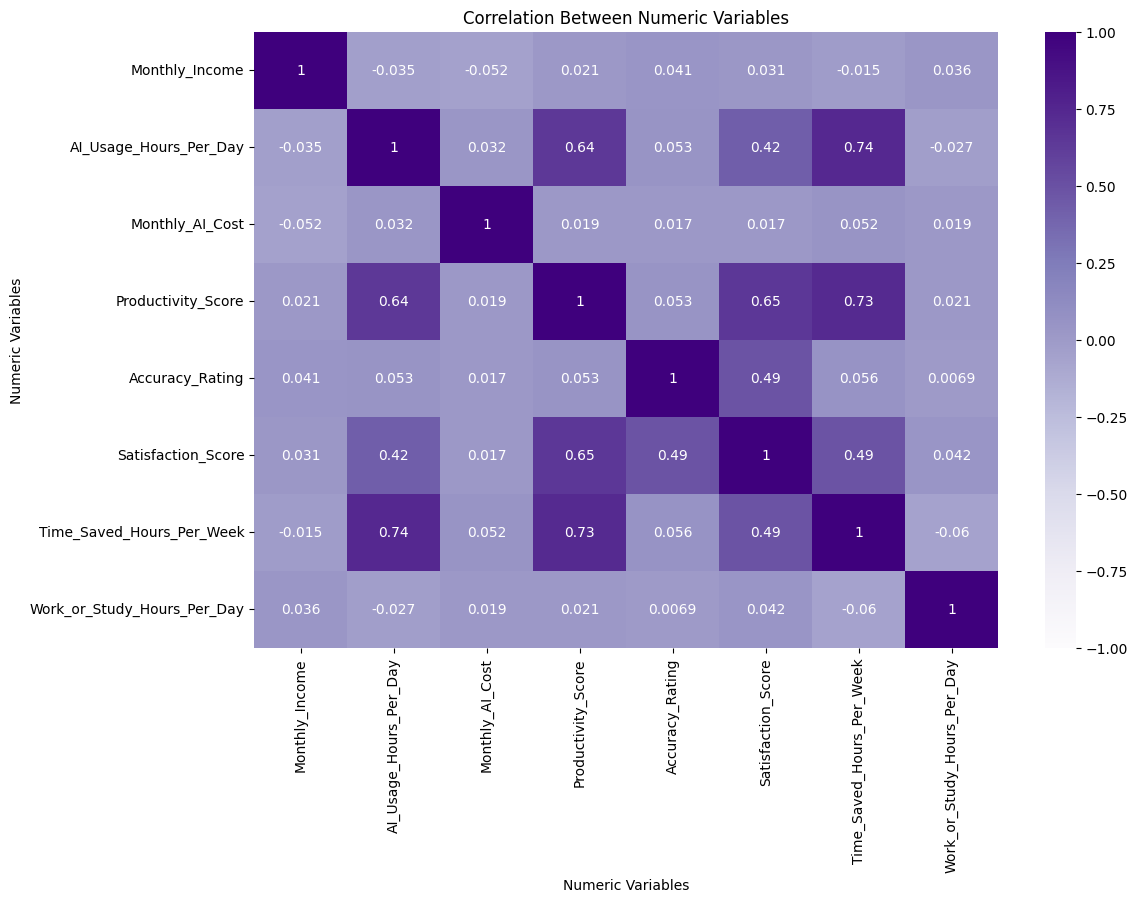

In [27]:
# Heatmap:
num_map  = df.select_dtypes(include="number")
correlation_matrix = num_map.corr()
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="Purples",
    vmin = -1,
    vmax = 1
)

plt.title("Correlation Between Numeric Variables")
plt.xlabel("Numeric Variables")
plt.ylabel("Numeric Variables")
plt.savefig("Numeric_Variables_Correlation")
plt.show()


INTERPRETATION OF HEATMAP:

This correlation heatmap shows relations between variables.
According to this, Productivity_Score has a positive relationship with Time Saved Hours Per Week (0.72) and Satisfaction Score(0.64).
AI Usage Hours Per day also has positive relationship with Time Saved Hours Per Week(0.74) and productivity_score(0.64).
Accurating rating has moderate positive relation with Satisfaction Score.

**STEP NO 04: Visualize Findings & Conclusions:**

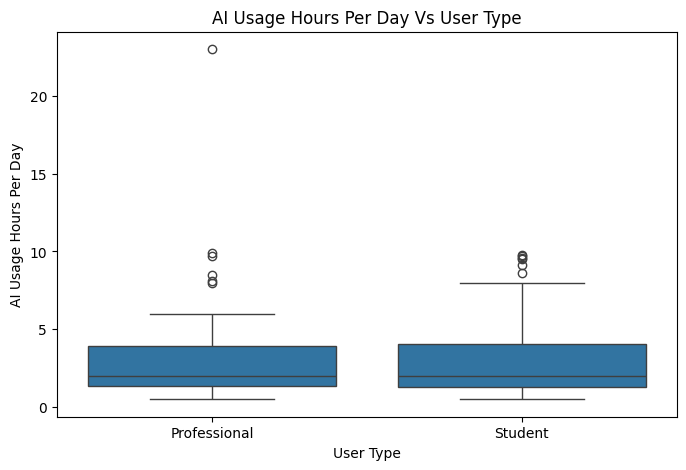

In [28]:
# Boxplot : AI Usage Hours Per Day Vs User Type

plt.figure(figsize=(8, 5))

sns.boxplot(
    data = df,
    x = "User_Type",
    y = "AI_Usage_Hours_Per_Day"
)

plt.title("AI Usage Hours Per Day Vs User Type")
plt.xlabel("User Type")
plt.ylabel("AI Usage Hours Per Day")
plt.savefig("AI Usage Hours Per Day Vs User Type")
plt.show()

INTERPRETATION OF BOXPLOT:
This compares the daily AI usage of Students and Professionals. Some users have much higher AI usage than others and these higher values are outliers and can affect the overall average AI usage.

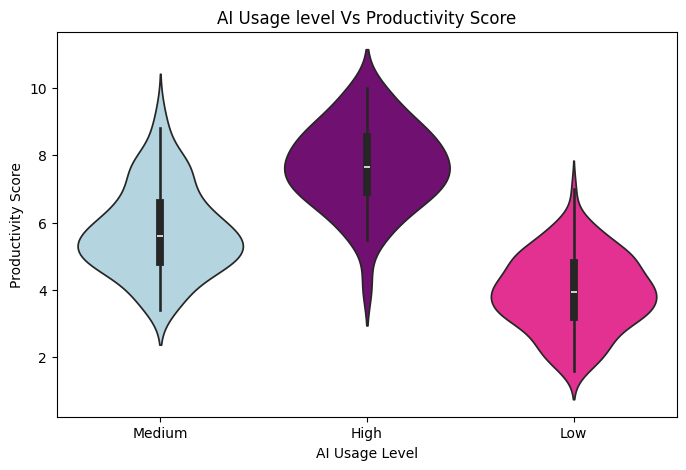

In [29]:
# Using Violinplot AI Usage level Vs Productivity Score:
plt.figure(figsize=(8, 5))

sns.violinplot(
   data = df,
   x = "Usage_Level",
   y = "Productivity_Score",
   palette= ["lightblue","purple","deeppink"],
   hue = "Usage_Level",

)

plt.title("AI Usage level Vs Productivity Score")
plt.xlabel("AI Usage Level")
plt.ylabel("Productivity Score")
plt.show()

INTERPRETATION :
The Voilin graph shows the productivity scores of people with low,medium and high AI usage.Higher AI usage increasee the productivity score in this data set.


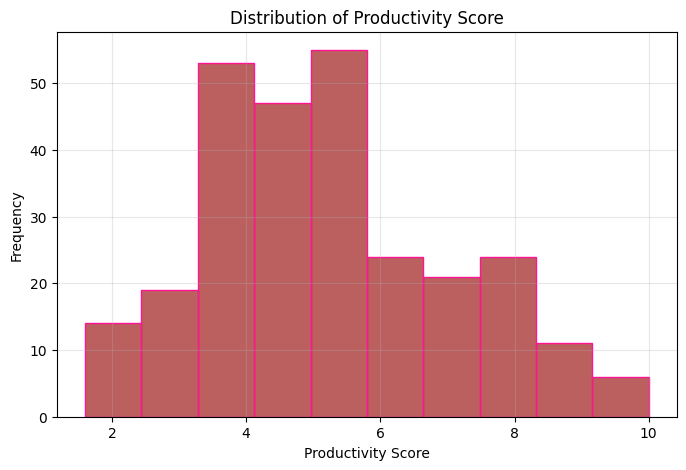

In [30]:
# Distribution : Productivity Score
plt.figure(figsize= (8,5))

sns.histplot(
    df["Productivity_Score"],
    bins = 10,
    color = "brown",
    edgecolor = "deeppink"
)

plt.title("Distribution of Productivity Score")
plt.xlabel("Productivity Score")
plt.ylabel("Frequency")
plt.grid(True, alpha = 0.3)
plt.show()

INTERPRETATION:
The histogram shows distribution of productivity scores. This shows productivity scores are concentrated around the middle of the scale,
while few at highest and lowest values.

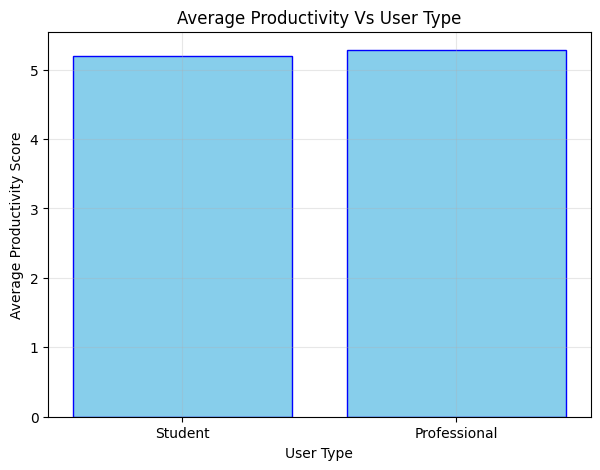

In [31]:
# Group Comparison:
group_mean = (
    df.groupby("User_Type")["Productivity_Score"].mean().reindex(
        ["Student", "Professional"]
    )
)

plt.figure(figsize= (7, 5))

plt.bar(
    group_mean.index,
    group_mean.values,
    color = "skyblue",
    edgecolor = "blue"
)

plt.title("Average Productivity Vs User Type")
plt.xlabel("User Type")
plt.ylabel("Average Productivity Score")
plt.grid(True , alpha = 0.3)
plt.show()

INTERPRETATION:
This bar chart compares average productivity between students and professionals.
The average scores of professionals and students are very similar, dataset only shows small difference between two grouops.

In [32]:
df["AI_Tool"]=df["AI_Tool"].str.strip().str.lower()

df["AI_Tool"] = df["AI_Tool"].replace({
    "chatgpt": "ChatGPT",
    "chat gpt" : "ChatGPT",
    "google gemini":"Google Gemini",
    "gemini" : "Google Gemini",
    "microsoft copilot":"Microsoft Copilot",
    "copilot": "Microsoft Copilot",
    "perplexity ai": "Perplexity AI",
    "grammarly" : "Grammarly",
    "deepseek" : "DeepSeek",
    "meta ai" : "Meta AI"

})

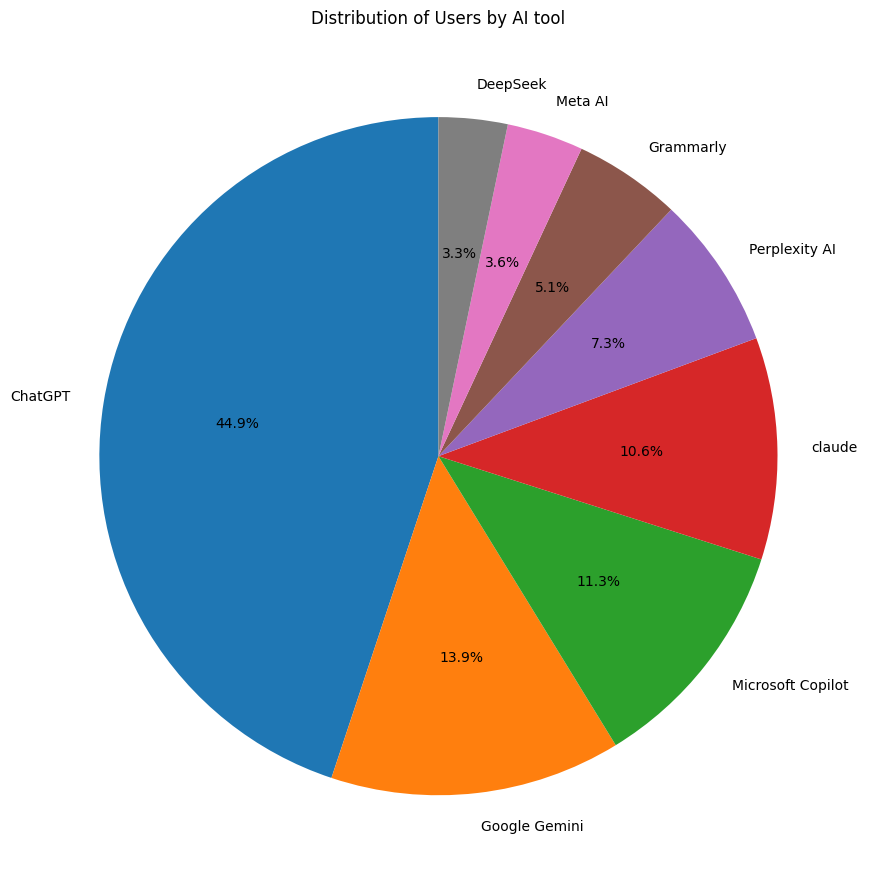

In [33]:
# Pie Chart AI tool:
tool_counts = df["AI_Tool"].value_counts()

plt.figure(figsize=(9, 9))

plt.pie(
    tool_counts.values,
    labels=tool_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Users by AI tool")
# plt.legend(average_productivity.index,title="AI Tools",loc="center left",bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()


**INTERPRETATION:**
This pie chart shows the percentage of users using each tool. According to this chatgpt is mostly used Ai tool.

AI_Tool
ChatGPT              5.300813
DeepSeek             5.533333
Google Gemini        5.060526
Grammarly            5.114286
Meta AI              5.150000
Microsoft Copilot    5.512903
Perplexity AI        4.640000
claude               5.293103
Name: Productivity_Score, dtype: float64


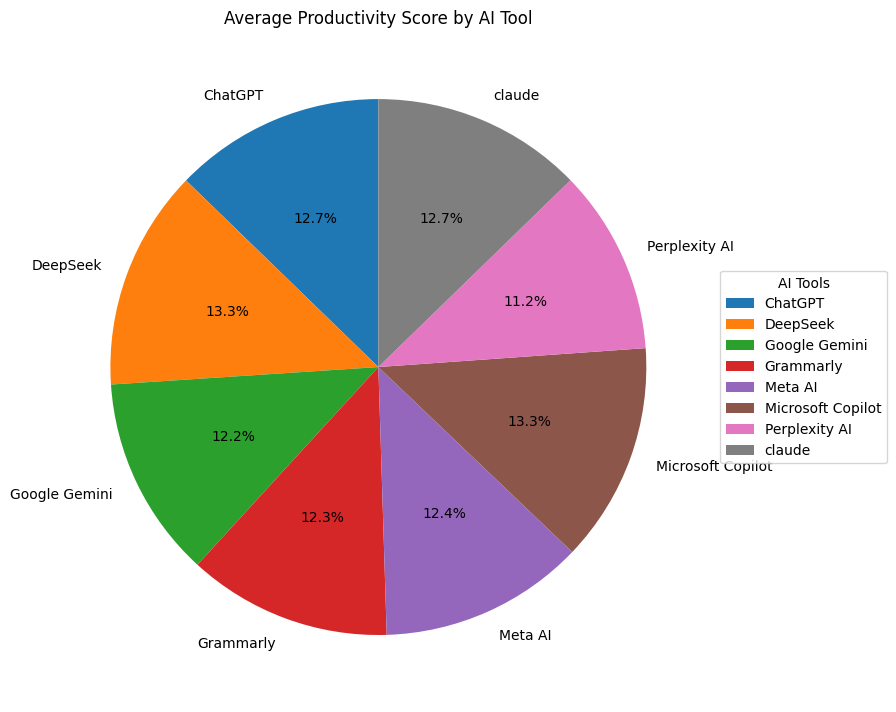

In [34]:
# Average Productivity score by AI tool
average_productivity = df.groupby("AI_Tool")["Productivity_Score"].mean()
print(average_productivity)

plt.figure(figsize=(9, 9))

plt.pie(
    average_productivity.values,
    labels = average_productivity.index,
    autopct = "%1.1f%%",
    startangle=90
)

plt.title("Average Productivity Score by AI Tool")
plt.legend(average_productivity.index,title="AI Tools",loc="center left",bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

**INTERPRETATION:**
This pie chart shows the average productivity score of each AI tool. According to this Deep Seek and Microsoft Copilot has highest average productivity score.

In [35]:
# Merging:

tool_list = pd.DataFrame({
    "AI_Tool" : [
        "Chatgpt","Claude","Google Gemini","Meta Ai",
        "Deepseek","Perplexity Ai", "Microsoft Copilot","Grammarly"
    ],

    "Tool_Category" : [
        "General AI","General AI","General AI","General AI",
        "Research AI","Research AI","Productive AI","Writting Ai"
    ]
})
print(tool_list)

# Merging it with:
df = df.merge(
    tool_list, on ="AI_Tool",how="left"
)

print(df[[
    "AI_Tool","Tool_Category"
]].head())

             AI_Tool  Tool_Category
0            Chatgpt     General AI
1             Claude     General AI
2      Google Gemini     General AI
3            Meta Ai     General AI
4           Deepseek    Research AI
5      Perplexity Ai    Research AI
6  Microsoft Copilot  Productive AI
7          Grammarly    Writting Ai
         AI_Tool Tool_Category
0        ChatGPT           NaN
1        ChatGPT           NaN
2        ChatGPT           NaN
3        Meta AI           NaN
4  Perplexity AI           NaN


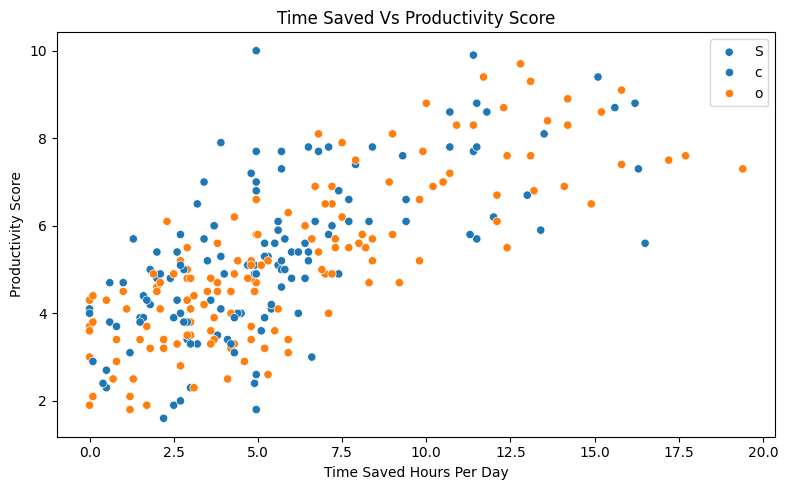

In [36]:
# Scatter Chart: Time Saved Vs Productivity Score

plt.figure(figsize = (8, 5))

sns.scatterplot(
    data=df,
    x="Time_Saved_Hours_Per_Week",
    y="Productivity_Score",
    hue="User_Type"
)

plt.title("Time Saved Vs Productivity Score")
plt.xlabel("Time Saved Hours Per Day")
plt.ylabel("Productivity Score")
plt.legend(labels = "Score")
plt.tight_layout()
plt.show()


INTERPRETATION:
This scatter plot shows a positive relationship between time saved and productivity scores. People who save more time using AI usually have higher productivity scores.

Would_Recommend
Maybe    5.675676
No       5.014706
Yes      6.704142
Name: Satisfaction_Score, dtype: float64


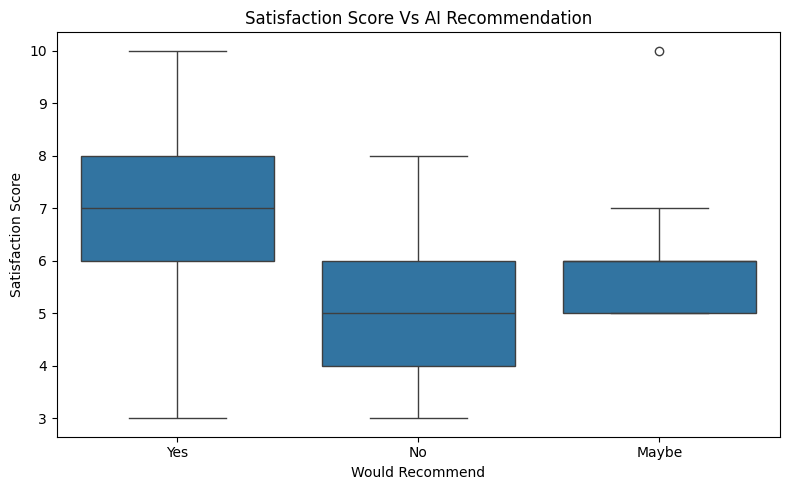

In [37]:
# Would Recommend Vs Satisfaction Score:
avg_satisfaction = df.groupby(
    "Would_Recommend"
)["Satisfaction_Score"].mean()

print(avg_satisfaction)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data = df,
    x = "Would_Recommend",
    y = "Satisfaction_Score"
)

plt.title("Satisfaction Score Vs AI Recommendation")
plt.xlabel("Would Recommend")
plt.ylabel("Satisfaction Score")
plt.tight_layout()
plt.show()

INTERPRETATION:
This boxplot compares the distribution of satisfaction scores between people who would recommend AI tools and those who would not.
In this "Yes" group shows higher satisfaction than "No".So overall positive assosiation between satisfaction and to recommend AI tools.

 CONCLUSION:

 Q.1:Using AI for more hours per day lead to higher productivity score?And which Ai tools are used by the largest proportion of users?And Also which Ai tool has the highest average productivity score?

 The data shows a positive relationship between AI usage hours per day and productivity score, with a correlation of 0.63.Acoording to this data Chapgpt used by most of the users.and Deep Seek has Highest average productivity score.

 Q.2: Difference in productivity levels between students and professionals?

 In this the average productivity score for professionals is 5.26 and students average productivity is 5.18.
 The Dataset does not show large difference in average productivity between two users.

 Q.3: Time saved,Satisfaction, and AI usage, which factor have the strongest relation with productivity?
 People with higher Satisfaction scores would recommend AI tools?

 Time saved through AI has the positive relationship with productivity having correlation of 0.75.
 Score and AI Usage hours per day also show positive relationship with productivity having correlation pf 0.64 and 0.63 respectively.
 Also dataset shows people with higher satisfaction scores would recommend AI tools.

In [38]:
# ML: Imports
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [39]:
ml = df.copy()
features = ["AI_Usage_Hours_Per_Day", "Time_Saved_Hours_Per_Week", "Satisfaction_Score"]

# Cap extreme AI usage values
ml["AI_Usage_Hours_Per_Day"] = ml["AI_Usage_Hours_Per_Day"].clip(upper=12)

# Binary target: High / Low productivity, split at the median
cut = ml["Productivity_Score"].median()
ml["Productivity_Class"] = np.where(ml["Productivity_Score"] >= cut, "High", "Low")

print("Median cut-off:", cut)
print(ml["Productivity_Class"].value_counts(normalize=True).round(3))

X = ml[features]
y = ml["Productivity_Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Median cut-off: 5.0
Productivity_Class
High    0.515
Low     0.485
Name: proportion, dtype: float64


In [40]:
rows = []


===== Decision Tree =====
Best parameters: {'model__max_depth': 2, 'model__min_samples_leaf': 10}
Test Accuracy: 0.8
              precision    recall  f1-score   support

        High       0.90      0.68      0.78        28
         Low       0.74      0.93      0.82        27

    accuracy                           0.80        55
   macro avg       0.82      0.80      0.80        55
weighted avg       0.82      0.80      0.80        55



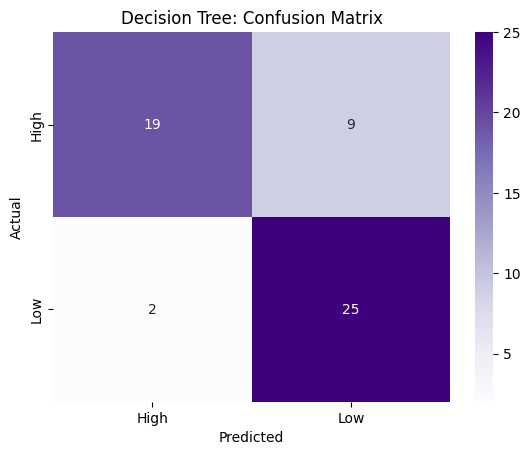

In [41]:
# 1. Build the pipeline: scale the data, then use the model
pipe_tree = Pipeline([
    ("scale", StandardScaler()),
    ("model", DecisionTreeClassifier(random_state=42))
])

# 2. Settings to try
grid_tree = {
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_leaf": [3, 5, 10]
}

# 3. Find the best settings using the training data
gs_tree = GridSearchCV(pipe_tree, grid_tree, cv=cv, scoring="accuracy")
gs_tree.fit(X_train, y_train)

# 4. Predict on the test data
pred_tree = gs_tree.predict(X_test)

# 5. Show results
print("===== Decision Tree =====")
print("Best parameters:", gs_tree.best_params_)
print("Test Accuracy:", accuracy_score(y_test, pred_tree))
print(classification_report(y_test, pred_tree))

# 6. Confusion matrix
sns.heatmap(
    confusion_matrix(y_test, pred_tree, labels=["High", "Low"]),
    annot=True, fmt="d", cmap="Purples",
    xticklabels=["High", "Low"], yticklabels=["High", "Low"]
)
plt.title("Decision Tree: Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 7. Save the scores for the final comparison
cv_tree = cross_val_score(gs_tree.best_estimator_, X, y, cv=cv).mean()
rows.append({"Model": "Decision Tree",
             "Test Accuracy": accuracy_score(y_test, pred_tree),
             "CV Accuracy": cv_tree})

===== KNN =====
Best parameters: {'model__n_neighbors': 7, 'model__weights': 'uniform'}
Test Accuracy: 0.8181818181818182
              precision    recall  f1-score   support

        High       0.82      0.82      0.82        28
         Low       0.81      0.81      0.81        27

    accuracy                           0.82        55
   macro avg       0.82      0.82      0.82        55
weighted avg       0.82      0.82      0.82        55



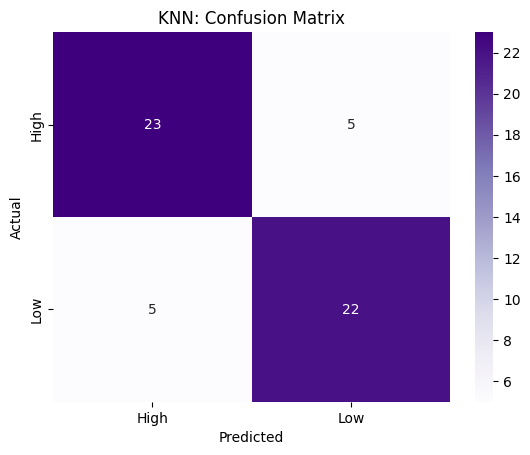

In [42]:
pipe_knn = Pipeline([
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier())
])

grid_knn = {
    "model__n_neighbors": [5, 7, 9, 11, 15],
    "model__weights": ["uniform", "distance"]
}

gs_knn = GridSearchCV(pipe_knn, grid_knn, cv=cv, scoring="accuracy")
gs_knn.fit(X_train, y_train)

pred_knn = gs_knn.predict(X_test)

print("===== KNN =====")
print("Best parameters:", gs_knn.best_params_)
print("Test Accuracy:", accuracy_score(y_test, pred_knn))
print(classification_report(y_test, pred_knn))

sns.heatmap(
    confusion_matrix(y_test, pred_knn, labels=["High", "Low"]),
    annot=True, fmt="d", cmap="Purples",
    xticklabels=["High", "Low"], yticklabels=["High", "Low"]
)
plt.title("KNN: Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

cv_knn = cross_val_score(gs_knn.best_estimator_, X, y, cv=cv).mean()
rows.append({"Model": "KNN",
             "Test Accuracy": accuracy_score(y_test, pred_knn),
             "CV Accuracy": cv_knn})

===== SVM =====
Best parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Test Accuracy: 0.8727272727272727
              precision    recall  f1-score   support

        High       0.96      0.79      0.86        28
         Low       0.81      0.96      0.88        27

    accuracy                           0.87        55
   macro avg       0.88      0.87      0.87        55
weighted avg       0.89      0.87      0.87        55



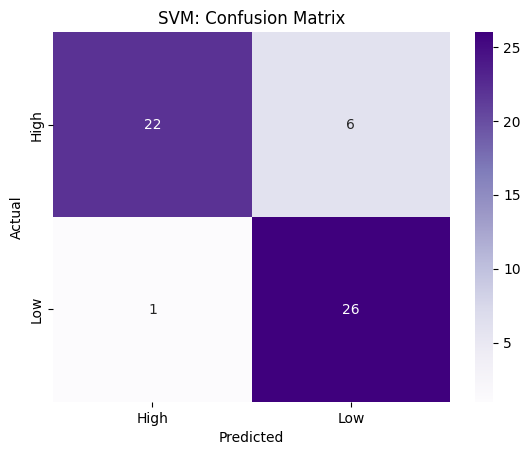

In [43]:
pipe_svm = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

grid_svm = {
    "model__kernel": ["linear", "rbf"],
    "model__C": [0.1, 1, 10],
    "model__gamma": ["scale", 0.1]
}

gs_svm = GridSearchCV(pipe_svm, grid_svm, cv=cv, scoring="accuracy")
gs_svm.fit(X_train, y_train)

pred_svm = gs_svm.predict(X_test)

print("===== SVM =====")
print("Best parameters:", gs_svm.best_params_)
print("Test Accuracy:", accuracy_score(y_test, pred_svm))
print(classification_report(y_test, pred_svm))

sns.heatmap(
    confusion_matrix(y_test, pred_svm, labels=["High", "Low"]),
    annot=True, fmt="d", cmap="Purples",
    xticklabels=["High", "Low"], yticklabels=["High", "Low"]
)
plt.title("SVM: Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

cv_svm = cross_val_score(gs_svm.best_estimator_, X, y, cv=cv).mean()
rows.append({"Model": "SVM",
             "Test Accuracy": accuracy_score(y_test, pred_svm),
             "CV Accuracy": cv_svm})

In [44]:
results = pd.DataFrame(rows).sort_values("CV Accuracy", ascending=False).reset_index(drop=True)
print(results.round(3))

           Model  Test Accuracy  CV Accuracy
0            SVM          0.873        0.814
1            KNN          0.818        0.799
2  Decision Tree          0.800        0.781


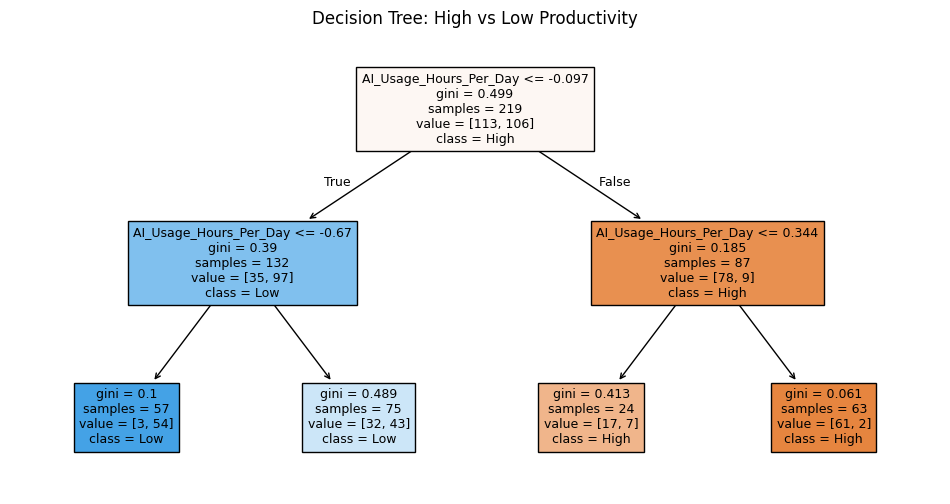

In [45]:
tree_model = gs_tree.best_estimator_.named_steps["model"]

plt.figure(figsize=(12, 6))
plot_tree(
    tree_model,
    feature_names=features,
    class_names=list(tree_model.classes_),
    filled=True,
    fontsize=9
)
plt.title("Decision Tree: High vs Low Productivity")
plt.show()

In [46]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [47]:
# Prepare data independently so this section can run after the EDA/ML cells
dl = df.copy()

features = [
    "AI_Usage_Hours_Per_Day",
    "Time_Saved_Hours_Per_Week",
    "Satisfaction_Score"
]
target_col = "Productivity_Score"

# Ensure required columns are numeric and remove rows with missing values
for col in features + [target_col]:
    dl[col] = pd.to_numeric(dl[col], errors="coerce")

dl = dl.dropna(subset=features + [target_col]).copy()
dl["AI_Usage_Hours_Per_Day"] = dl["AI_Usage_Hours_Per_Day"].clip(upper=12)

# Create High/Low classes using the median productivity score
median_score = dl[target_col].median()
dl["Productivity_Class"] = np.where(
    dl[target_col] >= median_score, "High", "Low"
)

X = dl[features].astype("float32")
y_text = dl["Productivity_Class"]

# Encode labels: High = 1, Low = 0
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Neural networks work better when numeric inputs are standardized
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype("float32")
X_test_scaled = scaler.transform(X_test).astype("float32")

print("Rows used:", len(dl))
print("Features:", features)
print("Class mapping:", dict(zip(label_encoder.classes_,
                                 label_encoder.transform(label_encoder.classes_))))
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Rows used: 274
Features: ['AI_Usage_Hours_Per_Day', 'Time_Saved_Hours_Per_Week', 'Satisfaction_Score']
Class mapping: {'High': np.int64(0), 'Low': np.int64(1)}
Training shape: (219, 3)
Testing shape: (55, 3)


In [48]:
# Build the neural network
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(16, activation="relu"),
    Dropout(0.20),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209 (836.00 B)

 Trainable params: 209 (836.00 B)

 Non-trainable params: 0 (0.00 B)

In [49]:
# Train the model with early stopping to reduce overfitting
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.20,
    epochs=25,
    batch_size=16,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - accuracy: 0.4571 - loss: 0.7477 - val_accuracy: 0.5909 - val_loss: 0.6588
Epoch 2/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.4571 - loss: 0.7158 - val_accuracy: 0.5909 - val_loss: 0.6426
Epoch 3/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.4571 - loss: 0.7107 - val_accuracy: 0.5909 - val_loss: 0.6274
Epoch 4/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.4629 - loss: 0.6901 - val_accuracy: 0.5909 - val_loss: 0.6127
Epoch 5/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4686 - loss: 0.6790 - val_accuracy: 0.6136 - val_loss: 0.5987
Epoch 6/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.4800 - loss: 0.6634 - val_accuracy: 0.5909 - val_loss: 0.5865
Epoch 7/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4914 - loss: 0.6522 - val_accuracy: 0.5909 - val_loss: 0.5763
Epoch 8/25
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.4971 - loss: 0.6376 - val_accuracy: 0.5909 - v

Test loss: 0.450
Test accuracy: 0.873
\nClassification report:
              precision    recall  f1-score   support

        High       0.96      0.79      0.86        28
         Low       0.81      0.96      0.88        27

    accuracy                           0.87        55
   macro avg       0.88      0.87      0.87        55
weighted avg       0.89      0.87      0.87        55



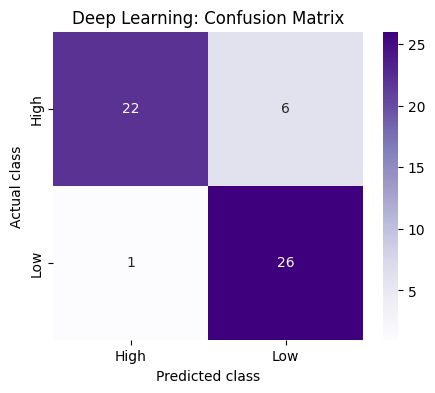

In [50]:
# Evaluate the model on unseen test data
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
probabilities = model.predict(X_test_scaled, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

print(f"Test loss: {test_loss:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")
print("\\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=[str(c) for c in label_encoder.classes_],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Purples",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.title("Deep Learning: Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.show()

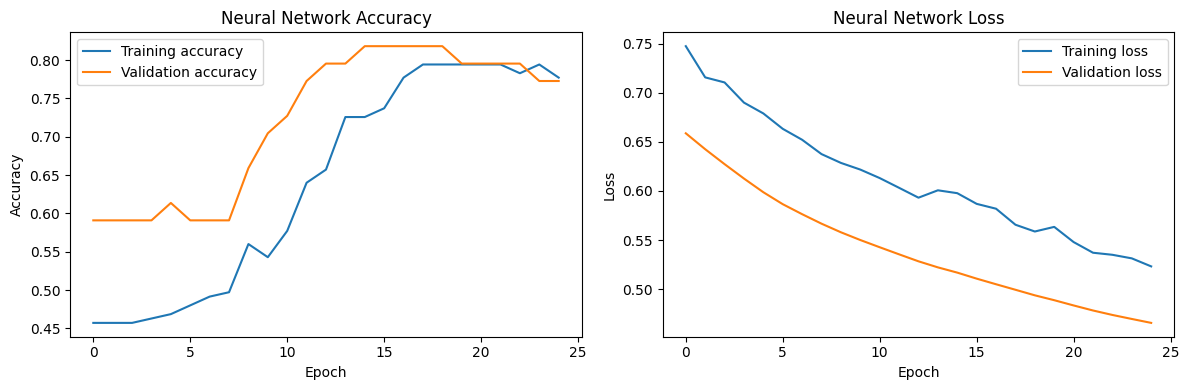

In [51]:
# Plot training and validation accuracy/loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Neural Network Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Neural Network Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()